# 1. Resultados de los experimentos del simulador (BFR vs FEniCS)

Este notebook **no corre simulaciones**: lee lo que dejó `python -m experimentos.correr` en
`data/output/experimentos/<grupo>/` (métricas, resúmenes y figuras finales) y lo ordena por pregunta. El detalle
de cada caso, con videos, está en `data/output/experimentos/informe.html` (`python -m experimentos.informe`).

| # | Grupo | Pregunta | Backends | Estado |
|---|---|---|---|---|
| A | `A_terminos` | ¿Cuánto aporta cada término (fuente, pozo) a la diferencia BFR↔FEM? | BFR + FEM | 4 casos, 30 d |
| B | `B_bc_salida_fem` | ¿Pesa la condición de salida del flujo de BFR (pfs frente a la tipo FEM)? | BFR (FEM = A) | 4 casos |
| C | `C_soporte_fuente` | ¿Influye lo localizada que está la fuente ($\sigma$)? | BFR + FEM | 6 casos |
| D | `D_caudal_pozo` | ¿Cómo cambian el cono y las velocidades con $Q$? | BFR + FEM | 4 casos |
| E | `E_paso_tiempo` | ¿Es temporal o espacial el error? | BFR + FEM | 2 casos |
| F | `F_upwind_bfr` | ¿Mejora el upwind de BFR? | BFR (FEM = A) | 2 casos |

**Importante — qué modelo se usó.** A–F se corrieron el 24-oct-2026 con el **modelo anterior**: el sumidero
$W_-$ estaba siempre activo (factor 1). Desde la decisión 1 (28-oct) el valor por defecto es 0. Las conclusiones
de flujo (A, B, D, E) no dependen de $W_-$; las de **C en el pozo sí** (ver §3).

El sumidero $W_-$ está anulado (`factor_sumidero_C = 0`): sobra en la forma no conservativa y los grupos S, W y Z se eliminaron.

In [1]:
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "..")
import rutas

pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
for g in ("A_terminos", "B_bc_salida_fem", "C_soporte_fuente", "D_caudal_pozo", "E_paso_tiempo",
          "F_upwind_bfr"):
    print(f"{g:18s} {rutas.grupo(g) or '— no hay resultados en ningún worktree'}")
R = pd.read_csv(rutas.archivo("resumen.csv"))
R["caso_corto"] = R["caso"].str.split("_").str[0]
print(f"\nresumen.csv: {len(R)} casos comparados")

A_terminos         /home/alex/dev/doctorado/codigo/data/output/experimentos/A_terminos
B_bc_salida_fem    /home/alex/dev/doctorado/codigo/data/output/experimentos/B_bc_salida_fem
C_soporte_fuente   /home/alex/dev/doctorado/codigo/data/output/experimentos/C_soporte_fuente
D_caudal_pozo      /home/alex/dev/doctorado/codigo/data/output/experimentos/D_caudal_pozo
E_paso_tiempo      /home/alex/dev/doctorado/codigo/data/output/experimentos/E_paso_tiempo
F_upwind_bfr       /home/alex/dev/doctorado/codigo/data/output/experimentos/F_upwind_bfr

resumen.csv: 27 casos comparados


## 0. Malla y configuración común

Malla compartida y congelada (`data/input/malla_compartida/malla.pkl`, generada con
`python -m preprocessing.malla_compartida`): 15 626 nodos del dominio + 862 fantasmas de BFR, 4 niveles (4/16/30/60
m), un nodo en cada esquina y triangulación con ángulo mínimo ≥ 28°. FEniCS usa esos mismos triángulos, así que la
comparación es **nodo a nodo**, sin interpolar.

Configuración de referencia (`experimentos/base.json`): ADR, fuente y pozo activos, $Q_{std}=0.3$, $r_{pozo}=20$ m,
$\Delta t=18\,000$ s, $T=30$ d, salida del flujo `pfs` en BFR, sin upwind.

**Cómo leer las métricas** (todas a $t=30$ d, normas con pesos de área nodal):

| métrica | qué es |
|---|---|
| `H_rms_final_m` | RMS de $H_{BFR}-H_{FEM}$ en metros |
| `V_L2_rel_final` | error relativo L2 de $\lvert\mathbf u\rvert$ |
| `C_L2_rel_final` | error relativo L2 de $C$ |
| `masa_ratio_final` | $\int C$ BFR / FEM |
| `Cpozo_bfr/fem_final` | C captada por el pozo ($\int g_\varepsilon C$) |

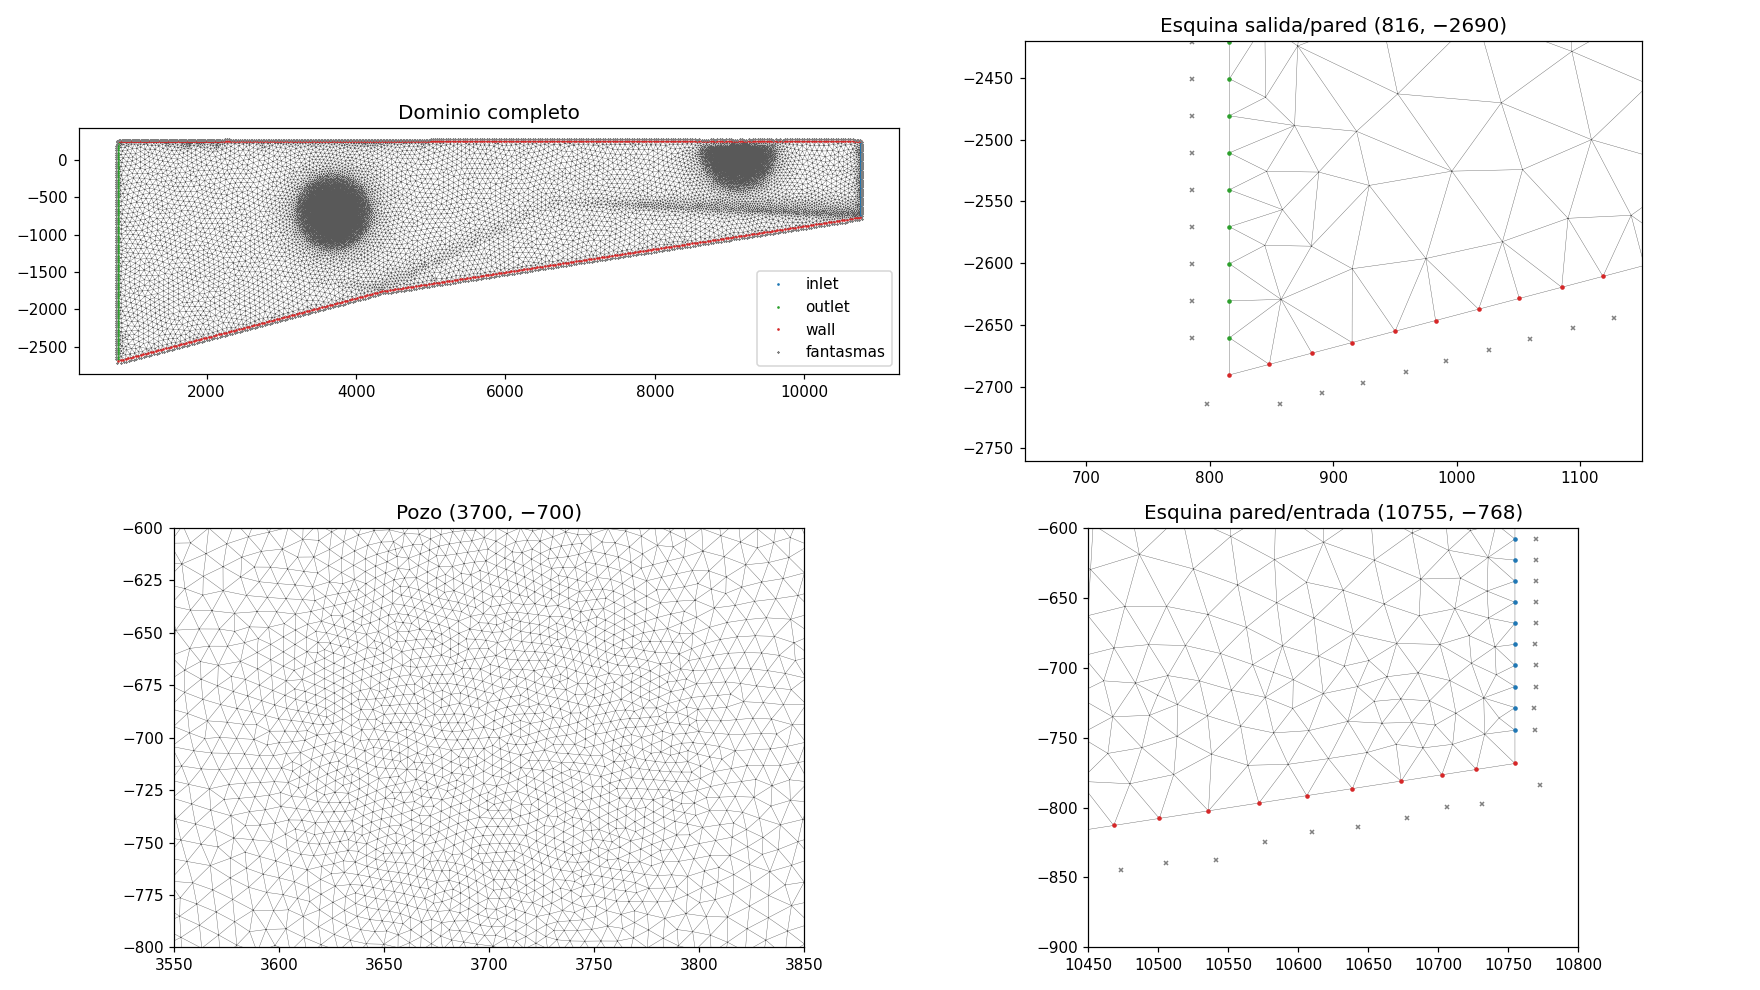

In [2]:
display(Image(filename=str(rutas.archivo("malla.png")), width=900))

In [3]:
COLS = ["H_rms_final_m", "V_L2_rel_final", "C_L2_rel_final", "masa_ratio_final", "Cpozo_bfr_final", "Cpozo_fem_final"]


def tabla(grupos):
    t = R[R["grupo"].isin(grupos)].set_index("caso")[COLS].copy()
    t["Cpozo BFR/FEM"] = t["Cpozo_bfr_final"] / t["Cpozo_fem_final"]
    return t.drop(columns=["Cpozo_bfr_final", "Cpozo_fem_final"])

## 1. Flujo: la condición de salida de BFR (grupos A y B)

In [4]:
display(tabla(["A_terminos", "B_bc_salida_fem"]))

,H_rms_final_m,V_L2_rel_final,C_L2_rel_final,masa_ratio_final,Cpozo BFR/FEM
caso,,,,,
A0_sin_fuente_sin_pozo,0.073,0.72,0.218,0.981,0.474
A1_solo_fuente,0.073,0.72,0.230,0.979,0.474
A2_solo_pozo,0.038,0.13,0.237,0.985,0.244
A3_fuente_pozo,0.038,0.13,0.245,0.982,0.244
B0_sin_fuente_sin_pozo,0.010,0.10,0.208,1.032,0.826
B1_solo_fuente,0.010,0.10,0.222,1.026,0.826
B2_solo_pozo,0.012,0.10,0.227,1.014,0.272
B3_fuente_pozo,0.012,0.10,0.236,1.010,0.272


* **La salida `pfs` de BFR causa casi toda la diferencia de flujo.** Sin pozo, A0 (pfs) tiene ΔH = 7.3 cm RMS y
  $\lvert\mathbf u\rvert$ 72 %; B0 (salida tipo FEM), 1 cm y 10 %. Con el pozo, el nivel del pozo coincide al
  milímetro con la salida tipo FEM.
* Lo que queda en B (≈1 cm RMS, 13 cm máximo) está en la franja de K baja junto a la pared inferior derecha
  ($\phi\approx0.03$): BFR evalúa $K\nabla^2H+\nabla K\cdot\nabla H$ con un $\nabla K$ de un campo con quiebres.
* Con `pfs`, BFR tiene además un transitorio inicial fuerte ($\lvert\mathbf u\rvert$ L2 hasta 0.8–1.0 en los
  primeros 5 días) porque la CI viene del FEM de la maestría.

**H y |U| a 30 d, A0 (pfs) — columnas BFR / FEM / diferencia:**

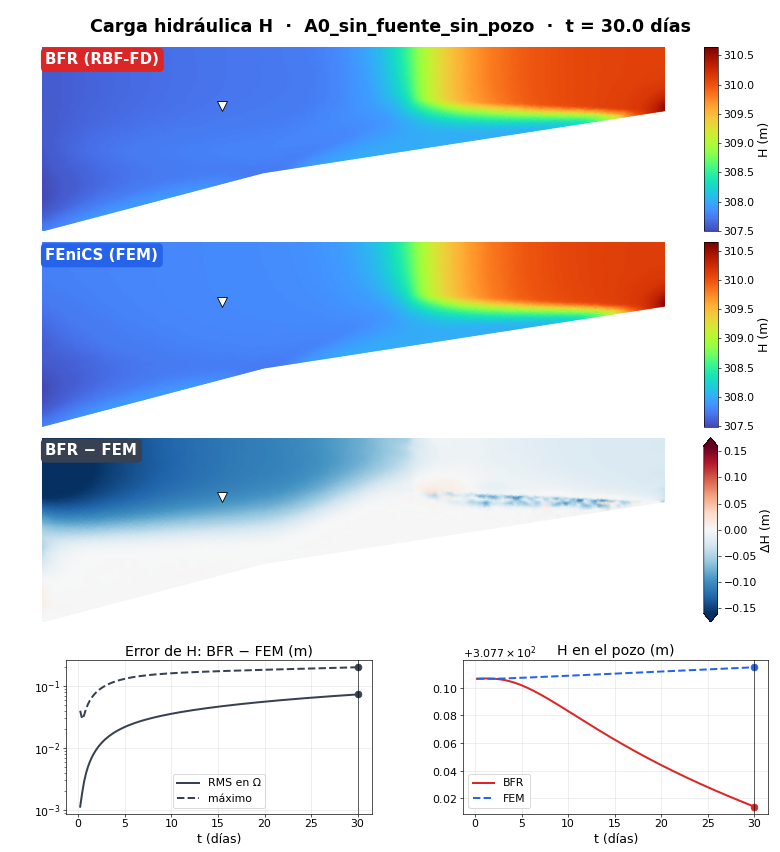

B0 (salida tipo FEM):


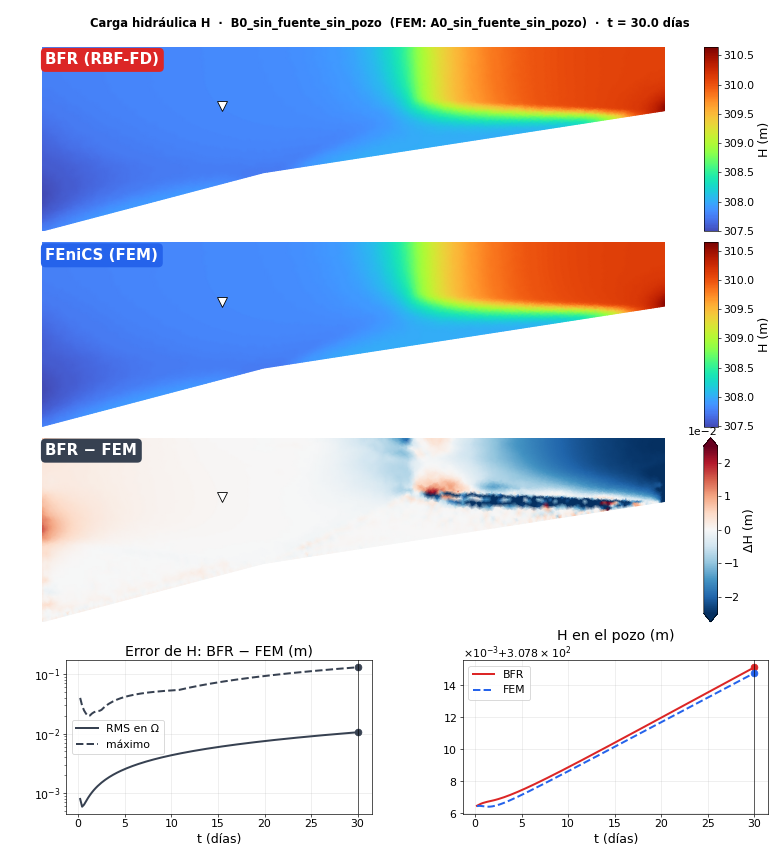

In [5]:
d = rutas.grupo("A_terminos") / "A0_sin_fuente_sin_pozo" / "comparacion"
display(Image(filename=str(d / "comparacion_H_final.png"), width=950))
d = rutas.grupo("B_bc_salida_fem") / "B0_sin_fuente_sin_pozo" / "comparacion"
if (d / "comparacion_H_final.png").exists():
    print("B0 (salida tipo FEM):")
    display(Image(filename=str(d / "comparacion_H_final.png"), width=950))

## 2. Transporte: fuente, paso de tiempo y upwind (grupos C, E, F)

In [6]:
display(tabla(["C_soporte_fuente", "E_paso_tiempo", "F_upwind_bfr"]))

,H_rms_final_m,V_L2_rel_final,C_L2_rel_final,masa_ratio_final,Cpozo BFR/FEM
caso,,,,,
C_sigma0p5_con_pozo,0.038,0.130,0.273,0.981,0.244
C_sigma0p5_sin_pozo,0.073,0.720,0.262,0.978,0.474
C_sigma2p0_con_pozo,0.038,0.130,0.229,0.983,0.244
C_sigma2p0_sin_pozo,0.073,0.720,0.211,0.980,0.474
C_sigma4p0_con_pozo,0.038,0.130,0.218,0.984,0.244
C_sigma4p0_sin_pozo,0.073,0.720,0.196,0.981,0.474
E_dt36000,0.038,0.131,0.244,0.982,0.245
E_dt7200,0.039,0.130,0.246,0.982,0.243
F1_upwind_solo_fuente,0.073,0.720,0.386,1.058,0.481


* **Diferencia estable de C de ≈20–27 % en L2**, también con el flujo casi igual (B), concentrada en el núcleo de
  la fuente: BFR conserva un pico más alto y estrecho, FEM (P2 sin SUPG) lo difunde más. Baja con una fuente más
  ancha: $\sigma$ = 0.5 → 0.26, 1 → 0.23, 2 → 0.21, 4 → 0.20.
* **La masa total** coincide al 1.5–3 %.
* **dt no influye** (E): ΔH 3.82/3.84/3.85 cm, C L2 0.244/0.245/0.246 con dt = 36 000/18 000/7 200 s. La
  diferencia es espacial o de formulación, y dt = 18 000 s basta.
* **Upwind de BFR** (F): ya no explota con la malla saneada, pero es peor que sin upwind (C L2 0.35–0.39 frente a
  0.23–0.25), crea puntos calientes y añade masa (+6 %). No usarlo en su forma actual.

**C a 30 d, A3 (fuente + pozo):**

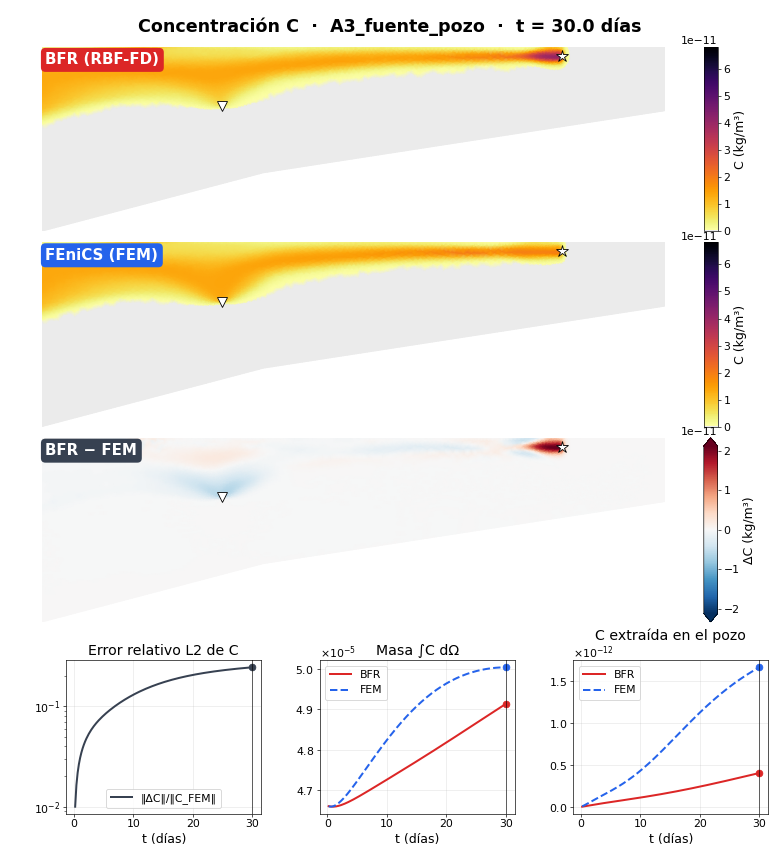

In [7]:
d = rutas.grupo("A_terminos") / "A3_fuente_pozo" / "comparacion"
display(Image(filename=str(d / "comparacion_C_final.png"), width=950))

## 3. El pozo: caudal y C extraída (grupo D)

In [8]:
display(tabla(["A_terminos", "D_caudal_pozo"]).loc[
    lambda t: t.index.str.contains("pozo|D_Q")])

,H_rms_final_m,V_L2_rel_final,C_L2_rel_final,masa_ratio_final,Cpozo BFR/FEM
caso,,,,,
A0_sin_fuente_sin_pozo,0.073,0.720,0.218,0.981,0.474
A2_solo_pozo,0.038,0.130,0.237,0.985,0.244
A3_fuente_pozo,0.038,0.130,0.245,0.982,0.244
D_Q1e-1,0.061,0.506,0.228,0.970,0.207
D_Q1e-2,0.072,0.701,0.219,0.980,0.150
D_Q3e-2,0.070,0.660,0.220,0.977,0.213
D_Q7e-1,0.022,0.337,0.232,1.059,0.465


* El 24-oct, con $W_-$ activo, **BFR extraía unas 4 veces menos C que FEM** (A3: 0.24). Con el pozo
  apagado, en el mismo punto la razón es 0.47–0.83: la pluma llega casi igual, así que la brecha estaba en el
  término del pozo.
* D: con $Q$ grande (0.7) ambos backends **crean masa sin fuente** (FEM 1.039, BFR 1.016). La causa está
  explicada: $\phi$ fijo en el transporte con $S_s=\phi$ en el flujo hace que el
  abatimiento cree masa aparente. No es culpa de $W_-$.

## 5. Qué es fiable hoy y qué no

| | fiable | no fiable todavía |
|---|---|---|
| flujo | BFR + salida tipo FEM: ΔH ≈ 1 cm, $\lvert\mathbf u\rvert$ 10 %, nivel del pozo idéntico | salida `pfs` (transitorio); franja de K baja (±13 cm) |
| transporte | masa total (1.5–3 %), forma de la pluma, independencia de dt | pico de la fuente (20–27 % L2); upwind BFR |
| pozo | masa extraída | C captada BFR/FEM (0.48 sin $W_-$) |
| balance | — | masa aparente por $S_s\partial_th$ con $\phi$ fijo y $S_s=\phi$ |

**Pendientes de corridas:** repetir A–F con `factor_sumidero_C = 0` (las cifras de C en el pozo de este
notebook son del modelo anterior).